# Week 2 - Preprocessing, part 2

# 1. Lesson: None

# 2. Weekly graph question

The Storytelling With Data book mentions planning on a "Who, What, and How" for your data story.  Write down a possible Who, What, and How for your data, using the ideas in the book.

**Who:**
Economic researchers, students, and analysts interested in understanding Ecuador's economic performance.

**What:**
I want to show how Ecuador's main economic indicators have changed over time, especially GDP growth, inflation, and unemployment.

**How:**
I will use historical economic data from 1995 to 2025 and create visualizations to compare trends and identify important changes in Ecuador's economy.

# 3. Homework - work with your chosen project datasets this semester

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do  Use Google, documentation, and ChatGPT to help you:

- Summarize the datasets using info() and describe()

- Are there any duplicate rows?

- Are there any duplicate values in a given column (when this would be inappropriate?)

- What are the mean, median, and mode of each column?

- Are there any missing or null values?

    - Do you want to fill in the missing value with a mean value?  A value of your choice?  Remove that row?

- Identify any other inconsistent data (e.g. someone seems to be taking an action before they are born.)

- Encode any categorical variables (e.g. with one-hot encoding.)

### Conclusions:

- Are the data usable?  If not, find some new data!

- Do you need to modify or correct the data in some way?

- Is there any class imbalance?  (Categories that have many more items than other categories).

In [5]:
df = pd.read_csv("ecuador_macro_long.csv")
df.head()

,year,indicator,indicator_name,value
0,1995,FP.CPI.TOTL,cpi_index_2010_100,6.919400e+00
1,1995,FP.CPI.TOTL.ZG,inflation_cpi_annual_pct,2.293410e+01
2,1995,NE.CON.PRVT.KD.ZG,household_consumption_growth_pct,3.984300e+00
3,1995,NY.GDP.MKTP.CD,gdp_current_usd,2.443288e+10
4,1995,NY.GDP.MKTP.KD.ZG,gdp_growth_annual_pct,2.252500e+00


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            275 non-null    int64  
 1   indicator       275 non-null    object 
 2   indicator_name  275 non-null    object 
 3   value           275 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 8.7+ KB


Since the value column contains different economic indicators with different units, its overall mean is not very useful. For this reason, I calculated the descriptive statistics separately for each indicator.

In [7]:
df.describe()

,year,value
count,275.000000,2.750000e+02
mean,2009.803636,7.852824e+09
std,8.873687,2.535214e+10
min,1995.000000,-1.219640e+01
25%,2002.000000,3.223550e+00
50%,2010.000000,6.403300e+00
75%,2017.000000,1.320347e+02
max,2025.000000,1.303206e+11


**Duplicate Values in Important Columns**

I checked for duplicate values using the combination of year and indicator. Since each economic indicator should have only one observation per year, this combination should be unique. No duplicates were found, so no records need to be removed.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.duplicated(subset=["year", "indicator"]).sum()

np.int64(0)

**Mean, Median, and Mode**

I calculated the mean, median, and mode for each economic indicator separately because the dataset contains different types of economic measurements.

For example, the average annual inflation was approximately 12.19%, while the median was 3.55%. This suggests that some years with higher inflation increased the overall average.

Most indicators did not have repeated numerical values, so they did not have a meaningful mode. The foreign exchange rate was an exception, with a mode of 1.0.

In [11]:
df.groupby("indicator_name")["value"].agg(["mean", "median"]).round(2)

,mean,median
indicator_name,,
cpi_index_2010_100,8.938000e+01,1.000000e+02
fx_rate_lcus_per_usd,8.713400e+02,1.000000e+00
gdp_current_usd,6.964709e+10,6.815133e+10
gdp_growth_annual_pct,2.970000e+00,3.730000e+00
household_consumption_growth_pct,2.420000e+00,3.630000e+00
inflation_cpi_annual_pct,1.219000e+01,3.550000e+00
oil_rents_pct_gdp,9.700000e+00,8.390000e+00
population,1.505587e+07,1.507670e+07
unemployment_pct,4.100000e+00,3.920000e+00


In [12]:
# Calculate the mode for each indicator

for indicator, group in df.groupby("indicator_name"):
    counts = group["value"].value_counts()

    if not counts.empty and counts.max() > 1:
        print(indicator, ":", group["value"].mode().tolist())
    else:
        print(indicator, ": No repeated value")


cpi_index_2010_100 : No repeated value
fx_rate_lcus_per_usd : [1.0]
gdp_current_usd : No repeated value
gdp_growth_annual_pct : No repeated value
household_consumption_growth_pct : No repeated value
inflation_cpi_annual_pct : No repeated value
oil_rents_pct_gdp : No repeated value
population : No repeated value
unemployment_pct : No repeated value


**Missing Values**

I used `isnull().sum()` to check for missing values in my dataset. The results showed no missing values in the existing records.

However, after checking the number of observations for each economic indicator, I noticed that oil rents only has 27 observations, while the other indicators have 31. The missing years are 2022, 2023, 2024, and 2025.

I decided to leave these observations unchanged rather than replace them with the mean, since using estimated values could affect the accuracy of my economic analysis.

In [13]:
df.isnull().sum()

,0
year,0
indicator,0
indicator_name,0
value,0


In [14]:
df.groupby("indicator_name")["year"].count()

,year
indicator_name,
cpi_index_2010_100,31
fx_rate_lcus_per_usd,31
gdp_current_usd,31
gdp_growth_annual_pct,31
household_consumption_growth_pct,31
inflation_cpi_annual_pct,31
oil_rents_pct_gdp,27
population,31
unemployment_pct,31


In [15]:
df_pivot = df.pivot(
    index="year",
    columns="indicator_name",
    values="value"
)

# Find the missing years for oil rents

df_pivot[df_pivot["oil_rents_pct_gdp"].isnull()].index.tolist()


[2022, 2023, 2024, 2025]

**Checking for Inconsistent Values**

I checked the minimum and maximum values for each economic indicator to identify possible inconsistencies.

I found some unusual values, including negative GDP growth in 2020 and high inflation in 2000. However, these values are economically possible and should not automatically be considered errors.

I also checked for invalid values, such as negative population or GDP and percentages outside the expected range. No invalid values were identified by these checks.

I noticed a significant change in the exchange rate around 2000, which may require additional context before comparing values across different years.

Based on these checks, I decided to keep the original observations unchanged.

In [16]:
df.groupby("indicator_name")["value"].agg(["min", "max"]).round(2)

,min,max
indicator_name,,
cpi_index_2010_100,6.920000e+00,1.339900e+02
fx_rate_lcus_per_usd,1.000000e+00,1.178680e+04
gdp_current_usd,1.753945e+10,1.303206e+11
gdp_growth_annual_pct,-9.250000e+00,9.420000e+00
household_consumption_growth_pct,-1.220000e+01,1.113000e+01
inflation_cpi_annual_pct,-3.400000e-01,9.610000e+01
oil_rents_pct_gdp,2.560000e+00,1.865000e+01
population,1.159051e+07,1.828990e+07
unemployment_pct,3.080000e+00,6.120000e+00


In [17]:
positive = [
    "population",
    "gdp_current_usd",
    "cpi_index_2010_100",
    "fx_rate_lcus_per_usd"
]

percentages = [
    "unemployment_pct",
    "oil_rents_pct_gdp"
]

invalid = df[
    (
        df["indicator_name"].isin(positive)
        & (df["value"] <= 0)
    )
    |
    (
        df["indicator_name"].isin(percentages)
        & (~df["value"].between(0, 100))
    )
]

invalid


,year,indicator,indicator_name,value


**Encoding Categorical Variables**

I identified two categorical columns in my dataset: indicator and indicator_name. Since both columns represent the same economic indicators, I decided to encode only indicator_name to avoid redundant information.

I used one-hot encoding with Pandas to convert the nine economic indicators into separate numerical columns containing 0 and 1.

I saved the encoded data in a new DataFrame to preserve the original dataset. This transformation makes the categorical information suitable for machine learning models.

In [18]:
df_encoded = pd.get_dummies(
    df.drop(columns=["indicator"]),
    columns=["indicator_name"],
    dtype=int
)

# Display the first five rows
df_encoded.head()


,year,value,indicator_name_cpi_index_2010_100,indicator_name_fx_rate_lcus_per_usd,indicator_name_gdp_current_usd,indicator_name_gdp_growth_annual_pct,indicator_name_household_consumption_growth_pct,indicator_name_inflation_cpi_annual_pct,indicator_name_oil_rents_pct_gdp,indicator_name_population,indicator_name_unemployment_pct
0,1995,6.919400e+00,1,0,0,0,0,0,0,0,0
1,1995,2.293410e+01,0,0,0,0,0,1,0,0,0
2,1995,3.984300e+00,0,0,0,0,1,0,0,0,0
3,1995,2.443288e+10,0,0,1,0,0,0,0,0,0
4,1995,2.252500e+00,0,0,0,1,0,0,0,0,0


In [19]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 11 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   year                                             275 non-null    int64  
 1   value                                            275 non-null    float64
 2   indicator_name_cpi_index_2010_100                275 non-null    int64  
 3   indicator_name_fx_rate_lcus_per_usd              275 non-null    int64  
 4   indicator_name_gdp_current_usd                   275 non-null    int64  
 5   indicator_name_gdp_growth_annual_pct             275 non-null    int64  
 6   indicator_name_household_consumption_growth_pct  275 non-null    int64  
 7   indicator_name_inflation_cpi_annual_pct          275 non-null    int64  
 8   indicator_name_oil_rents_pct_gdp                 275 non-null    int64  
 9   indicator_name_population       

### Conclusions

**Are the data usable?**

Yes, the dataset appears usable for my project. It contains 275 observations across nine economic indicators, with no duplicated rows or null values in the existing records. However, the oil-rents indicator is missing observations for 2022–2025.

**Do you need to modify or correct the data?**

I did not identify any values that clearly needed to be removed. Some unusual economic values may represent real economic conditions. I also applied one-hot encoding to convert the categorical variables into numerical columns. I decided to keep the original observations unchanged for now.

**Is there any class imbalance?**

The dataset does not have a defined classification target, but I checked the distribution of observations across economic indicators. Eight indicators have 31 observations each, while oil rents has 27. The distribution is relatively balanced, although oil rents has fewer observations because of its missing years.

In [20]:
df["indicator_name"].value_counts()

,count
indicator_name,
cpi_index_2010_100,31
inflation_cpi_annual_pct,31
household_consumption_growth_pct,31
gdp_current_usd,31
gdp_growth_annual_pct,31
fx_rate_lcus_per_usd,31
unemployment_pct,31
population,31
oil_rents_pct_gdp,27


In [21]:
df["indicator_name"].value_counts(normalize=True) * 100

,proportion
indicator_name,
cpi_index_2010_100,11.272727
inflation_cpi_annual_pct,11.272727
household_consumption_growth_pct,11.272727
gdp_current_usd,11.272727
gdp_growth_annual_pct,11.272727
fx_rate_lcus_per_usd,11.272727
unemployment_pct,11.272727
population,11.272727
oil_rents_pct_gdp,9.818182


# 4. Storytelling With Data graph

Just like last week: choose any graph in the Introduction of Storytelling With Data (p. 1-17). Use matplotlib to reproduce it in a rough way. I don't expect you to spend an enormous amount of time on this; I understand that you likely will not have time to re-create every feature of the graph. However, if you're excited about learning to use matplotlib, this is a good way to do that. You don't have to duplicate the exact values on the graph; just the same rough shape will be enough.  If you don't feel comfortable using matplotlib yet, do the best you can and write down what you tried or what Google searches you did to find the answers.

I selected Figure 0.3 from page 4 of the Introduction of *Storytelling With Data*.

I used Matplotlib to recreate the ticket volume graph, comparing the number of tickets received and processed throughout the year.

The graph illustrates how processed tickets started falling behind received tickets during the second half of the year. This example helped me understand how data visualization can communicate information more clearly.

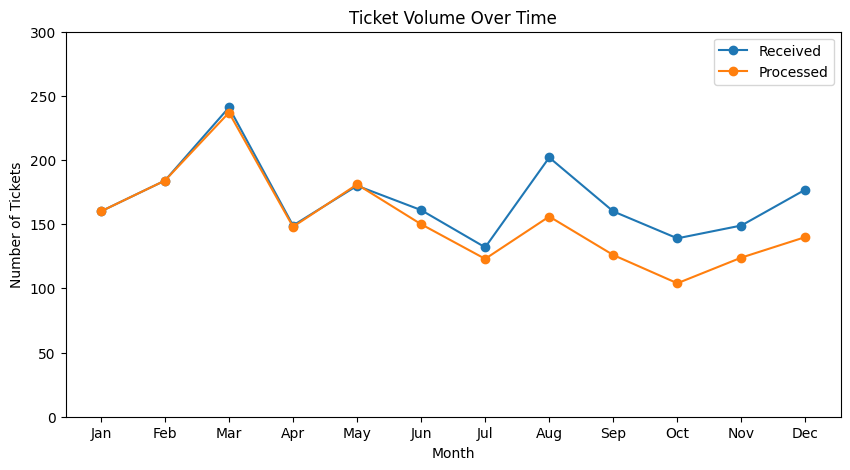

In [22]:
import matplotlib.pyplot as plt

# Months of the year
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Ticket values from the book
received = [160, 184, 241, 149, 180, 161,
            132, 202, 160, 139, 149, 177]

processed = [160, 184, 237, 148, 181, 150,
             123, 156, 126, 104, 124, 140]

# Create the graph
plt.figure(figsize=(10, 5))

# Plot the two lines
plt.plot(months, received, marker="o", label="Received")
plt.plot(months, processed, marker="o", label="Processed")

# Add the title and labels
plt.title("Ticket Volume Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Tickets")

# Display the legend
plt.legend()

# Set the vertical axis range
plt.ylim(0, 300)

# Display the graph
plt.show()
